# Appendix C — Solutions to the Exercises

This appendix collects the solutions of the exercises, chapter by chapter. It grows as the book grows: each new chapter adds its own section.

**How to use it.** Try the exercise first, then read the hint in the chapter, and only then look here. For the manual exercises the solution is written out in full. For the computational exercises the solution is a complete, executable piece of code, followed by a short discussion of what the output shows; there are many correct ways to write such code, and yours may differ.

**A note on the code.** Each solution lives in a function (`solution_1_6()`, and so on), so that the cells do not overwrite each other's variables. The function names match the exercise numbers.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

# Same plotting style and color-blind-safe palette as in the chapters
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## C.1 Chapter 1

### Manual exercises

**Solution 1.1 — Name the problem.**

| Task | Paradigm | Type |
|---|---|---|
| (a) tomorrow's electricity consumption | supervised | regression (the target is a real number) |
| (b) grouping customers without predefined groups | unsupervised | clustering (Chapter 12) |
| (c) spam or not spam | supervised | classification (two classes) |
| (d) learning a game by self-play, from wins and losses | reinforcement learning | the wins and losses are the reward signal (Chapter 22) |
| (e) reducing 1000 measurements to 10 numbers | unsupervised | dimensionality reduction (Chapter 13) |

**Solution 1.2 — Shapes.**
(a) $\mathbf{X} \in \mathbb{R}^{200 \times 5}$ and $\mathbf{y} \in \mathbb{R}^{200}$.
(b) The intercept column adds one column: $200 \times 6$.
(c) $\mathbf{X}^\top\mathbf{X}$ is $d \times d$, that is $5 \times 5$ (and $6 \times 6$ for the design matrix with the intercept). Its size depends on the number of features, not on the number of samples.
(d) Each entry of $\mathbf{X}\mathbf{w}$ is the dot product of a row of $\mathbf{X}$ with $\mathbf{w}$:

$$
\mathbf{X}\mathbf{w} = \begin{pmatrix} 1\cdot 1 + 2\cdot(-1) \\ 3\cdot 1 + 4\cdot(-1) \\ 5\cdot 1 + 6\cdot(-1) \end{pmatrix} = \begin{pmatrix} -1 \\ -1 \\ -1 \end{pmatrix}.
$$

The $i$-th entry is the prediction of the linear model $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x}$ for the $i$-th sample; here, the first feature minus the second.

**Solution 1.3 — Least squares by hand.** The points are $(0,2)$, $(1,2)$, $(2,5)$.

(a) $\mathbf{X} = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}$, $\mathbf{y} = \begin{pmatrix} 2 \\ 2 \\ 5 \end{pmatrix}$. Then $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix}$ and $\mathbf{X}^\top\mathbf{y} = \begin{pmatrix} 9 \\ 12 \end{pmatrix}$. With $\det = 6$,

$$
\hat{\mathbf{w}} = \frac{1}{6}\begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}\begin{pmatrix} 9 \\ 12 \end{pmatrix}
= \frac{1}{6}\begin{pmatrix} 9 \\ 9 \end{pmatrix} = \begin{pmatrix} 3/2 \\ 3/2 \end{pmatrix},
$$

so the line is $\hat{y} = \tfrac32 + \tfrac32 x$.

(b) $\hat{\mathbf{y}} = (1.5,\ 3,\ 4.5)^\top$, hence $\mathbf{r} = \mathbf{y} - \hat{\mathbf{y}} = (0.5,\ -1,\ 0.5)^\top$. Then $\sum_i r_i = 0$ and $\mathbf{r}\cdot(0,1,2) = 0 - 1 + 1 = 0$: $\mathbf{X}^\top\mathbf{r} = \mathbf{0}$.

(c) $\text{MSE} = \frac{0.25 + 1 + 0.25}{3} = 0.5$. The mean of $\mathbf{y}$ is $3$ and $\sum_i (y_i - \bar y)^2 = 1 + 1 + 4 = 6$, so $R^2 = 1 - \frac{1.5}{6} = 0.75$.

**Solution 1.4 — Derive it yourself.**
(a) $L(w) = \sum_i (y_i - w x_i)^2$, so $L'(w) = -2\sum_i x_i (y_i - w x_i)$. Setting $L'(w) = 0$ gives $\sum_i x_i y_i = w \sum_i x_i^2$, that is

$$
\hat{w} = \frac{\sum_i x_i y_i}{\sum_i x_i^2}.
$$

(b) With a single column $\mathbf{x} = (x_1, \dots, x_n)^\top$ as the data matrix, $\mathbf{X}^\top\mathbf{X} = \mathbf{x}^\top\mathbf{x} = \sum_i x_i^2$ (a $1\times 1$ matrix) and $\mathbf{X}^\top\mathbf{y} = \sum_i x_i y_i$, so $(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$ is the same ratio.

(c) $L''(w) = 2\sum_i x_i^2$, which is strictly positive unless every $x_i$ is zero. Hence $L$ is strictly convex and $\hat{w}$ is its unique minimizer.

**Solution 1.5 — Which loss, which constant?**
(a) $f(c) = \sum_i (y_i - c)^2$ has $f'(c) = -2\sum_i (y_i - c)$, which vanishes at $c = \frac1n\sum_i y_i$; and $f'' = 2n > 0$. The minimizer is the mean.

(b) Let $g(c) = \sum_i \lvert y_i - c\rvert$, with $n = 2m - 1$ and $m = (n+1)/2$. The function $g$ is piecewise linear. At a point $c$ that is not a data point, $g'(c) = \#\{y_i < c\} - \#\{y_i > c\}$ (each term with $y_i < c$ contributes $+1$, each term with $y_i > c$ contributes $-1$).
- For $c$ between $y_{(m-1)}$ and $y_{(m)}$: $m - 1$ points lie below and $m$ above, so $g' = -1 < 0$.
- For $c$ between $y_{(m)}$ and $y_{(m+1)}$: $m$ points lie below and $m - 1$ above, so $g' = +1 > 0$.

More generally the slope is $2k - n$ when $k$ points lie below $c$, which is negative for $k < m$ and positive for $k \ge m$. So $g$ decreases up to $y_{(m)}$ and increases afterwards: the minimizer is $y_{(m)}$, the median.

(c) Replace $y_n$ by $10^6$. The order of the points is unchanged (it was already the largest, and it only grows), so the **median is unchanged**. The **mean** instead moves by $(10^6 - y_n)/n$, which can be enormous: one outlier drags the optimal constant of the squared loss arbitrarily far. The squared loss is therefore sensitive to outliers (it squares large errors), while the absolute loss is robust. When the data may contain outliers, the choice of loss matters as much as the choice of model.

### Python exercises

**Solution 1.6 — Meet a new data set.**

In [3]:
def solution_1_6():
    from sklearn.datasets import load_wine

    wine = load_wine(as_frame=True)
    X, y = wine.data, wine.target
    print("shape of X:", X.shape)
    print("classes:", dict(zip(wine.target_names.tolist(), np.bincount(y).tolist())))
    print("first five features:", X.columns[:5].tolist())

    stats = X.describe().loc[["mean", "std"]].T
    print("\nmean and standard deviation of each feature:")
    print(stats.round(3).to_string())
    print("\nfeature with the largest standard deviation:", stats["std"].idxmax())

solution_1_6()

shape of X: (178, 13)
classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}
first five features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']

mean and standard deviation of each feature:
                                 mean      std
alcohol                        13.001    0.812
malic_acid                      2.336    1.117
ash                             2.367    0.274
alcalinity_of_ash              19.495    3.340
magnesium                      99.742   14.282
total_phenols                   2.295    0.626
flavanoids                      2.029    0.999
nonflavanoid_phenols            0.362    0.124
proanthocyanins                 1.591    0.572
color_intensity                 5.058    2.318
hue                             0.957    0.229
od280/od315_of_diluted_wines    2.612    0.710
proline                       746.893  314.907

feature with the largest standard deviation: proline


The Wine data set has 178 samples, 13 features, and 3 classes. The feature `proline` lives on a scale of hundreds (its mean is in the 700s and its standard deviation above 300), while most other features are of order 1 to 100 and some are below 1. In a distance-based method such as k-NN, `proline` would dominate the Euclidean distance and the other features would barely matter: **standardize the features** first (Section 1.8).

**Solution 1.7 — A line on Iris.**

normal equations: [-0.36308  0.41576]
lstsq           : [-0.36308  0.41576]
scikit-learn    : [-0.36308  0.41576]
all agree: True

MSE = 0.0421 | baseline MSE = 0.5771 | R^2 = 0.9271


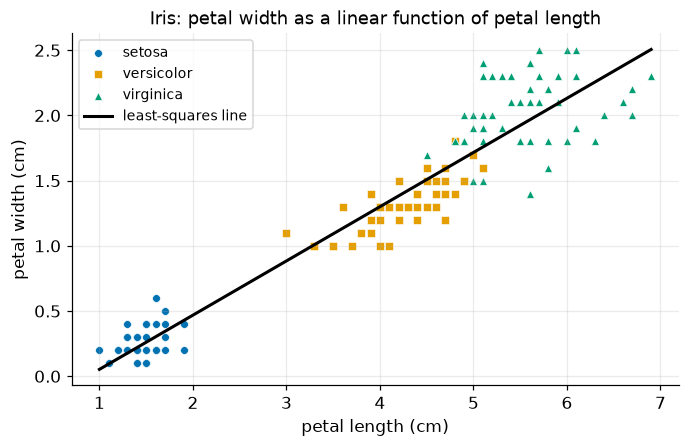

In [4]:
def solution_1_7():
    from sklearn.datasets import load_iris
    from sklearn.linear_model import LinearRegression

    iris = load_iris(as_frame=True)
    x = iris.data["petal length (cm)"].to_numpy()
    t = iris.data["petal width (cm)"].to_numpy()
    A = np.column_stack([np.ones_like(x), x])

    # (a) three ways to the same answer
    w_normal = np.linalg.solve(A.T @ A, A.T @ t)
    w_lstsq = np.linalg.lstsq(A, t, rcond=None)[0]
    lr = LinearRegression().fit(x.reshape(-1, 1), t)
    w_sk = np.array([lr.intercept_, lr.coef_[0]])
    print("normal equations:", w_normal.round(5))
    print("lstsq           :", w_lstsq.round(5))
    print("scikit-learn    :", w_sk.round(5))
    print("all agree:", np.allclose(w_normal, w_lstsq) and np.allclose(w_normal, w_sk))

    # (b) error, baseline, R^2
    t_hat = A @ w_normal
    mse = np.mean((t - t_hat) ** 2)
    mse_base = np.mean((t - t.mean()) ** 2)
    r2 = 1 - np.sum((t - t_hat) ** 2) / np.sum((t - t.mean()) ** 2)
    print(f"\nMSE = {mse:.4f} | baseline MSE = {mse_base:.4f} | R^2 = {r2:.4f}")

    # (c) plot
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    species = iris.target.to_numpy()
    for k, (name, color, marker) in enumerate(zip(iris.target_names, [BLUE, ORANGE, GREEN], ["o", "s", "^"])):
        ax.scatter(x[species == k], t[species == k], s=26, color=color, marker=marker,
                   edgecolor="white", linewidth=0.4, label=name)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, w_normal[0] + w_normal[1] * xs, color="black", linewidth=2, label="least-squares line")
    ax.set_xlabel("petal length (cm)")
    ax.set_ylabel("petal width (cm)")
    ax.set_title("Iris: petal width as a linear function of petal length")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

solution_1_7()

The three methods agree to numerical precision. The line explains more than 90% of the variance of the petal width (compare the MSE with the baseline MSE, and read the $R^2$): on this data set the two petal measurements are strongly linearly related. Note that the cloud is not homogeneous across species, and the line is a compromise between the three groups.

**Solution 1.8 — Does scaling matter?**

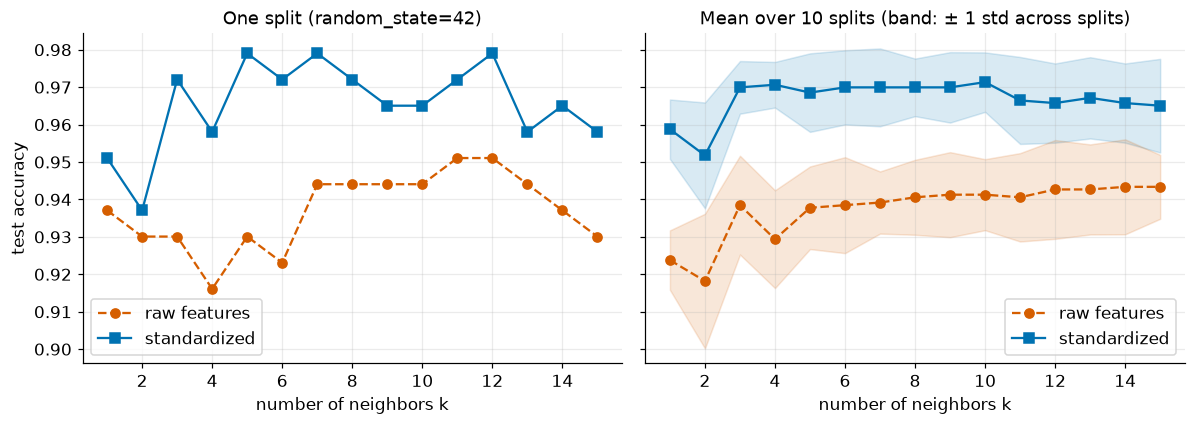

mean accuracy gain from scaling: 0.029
fraction of (split, k) pairs where scaling is at least as good: 1.000
fraction where scaling is strictly better: 0.987


In [5]:
def solution_1_8():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True, as_frame=True)
    ks = np.arange(1, 16)

    def test_accuracies(seed):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
        raw = [KNeighborsClassifier(k).fit(X_tr, y_tr).score(X_te, y_te) for k in ks]
        scaled = [make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(X_tr, y_tr).score(X_te, y_te)
                  for k in ks]
        return raw, scaled

    # the split of Section 1.8 (random_state = SEED)
    raw_1, scaled_1 = test_accuracies(SEED)
    # ten different splits
    seeds = range(10)
    all_raw, all_scaled = map(np.array, zip(*(test_accuracies(s) for s in seeds)))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    axes[0].plot(ks, raw_1, "o--", color=VERMILION, label="raw features")
    axes[0].plot(ks, scaled_1, "s-", color=BLUE, label="standardized")
    axes[0].set_title(f"One split (random_state={SEED})")
    axes[1].plot(ks, all_raw.mean(axis=0), "o--", color=VERMILION, label="raw features")
    axes[1].plot(ks, all_scaled.mean(axis=0), "s-", color=BLUE, label="standardized")
    axes[1].fill_between(ks, all_scaled.mean(0) - all_scaled.std(0), all_scaled.mean(0) + all_scaled.std(0),
                         color=BLUE, alpha=0.15)
    axes[1].fill_between(ks, all_raw.mean(0) - all_raw.std(0), all_raw.mean(0) + all_raw.std(0),
                         color=VERMILION, alpha=0.15)
    axes[1].set_title("Mean over 10 splits (band: ± 1 std across splits)")
    for ax in axes:
        ax.set_xlabel("number of neighbors k")
        ax.legend()
    axes[0].set_ylabel("test accuracy")
    fig.tight_layout()
    plt.show()

    diff = all_scaled - all_raw                      # shape (10 splits, 15 values of k)
    print(f"mean accuracy gain from scaling: {diff.mean():.3f}")
    print(f"fraction of (split, k) pairs where scaling is at least as good: {(diff >= 0).mean():.3f}")
    print(f"fraction where scaling is strictly better: {(diff > 0).mean():.3f}")

solution_1_8()

The conclusion is stable. Averaged over the ten splits, standardized features give a higher test accuracy for essentially every $k$ (the gain is about three percentage points in our run), and the printed fractions show that scaling was never worse and almost always strictly better across all the (split, $k$) pairs. A single split would have been enough to see the effect here, but *only* repeating the experiment lets us say that the conclusion does not depend on the lucky choice of one split. This habit, repeating the evaluation on several splits, is formalized as cross-validation in Chapter 5.

**Solution 1.9 — Your own overfitting experiment.**

In [6]:
def solution_1_9():
    from numpy.polynomial import polynomial as P
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split

    d = load_diabetes(as_frame=True, scaled=False)
    target = d.target.to_numpy()
    MAX_DEG, N_SPLITS = 8, 100

    def median_test_errors(z, n_train):
        errs = np.zeros((N_SPLITS, MAX_DEG + 1))
        for s in range(N_SPLITS):
            z_tr, z_te, y_tr, y_te = train_test_split(z, target, train_size=n_train, random_state=s)
            for degree in range(MAX_DEG + 1):
                coef = P.polyfit(z_tr, y_tr, degree)
                errs[s, degree] = np.mean((y_te - P.polyval(z_te, coef)) ** 2)
        return np.median(errs, axis=0)

    rows = []
    for feature in ["bp", "s5"]:
        f = d.data[feature].to_numpy()
        z = (f - f.mean()) / f.std()
        for n_train in [30, 100, 300]:
            med = median_test_errors(z, n_train)
            rows.append({"feature": feature, "training size": n_train,
                         "best degree": int(med.argmin()),
                         "test MSE at best degree": round(float(med.min()), 0),
                         "test MSE at degree 1 (a line)": round(float(med[1]), 0),
                         "test MSE at degree 0 (baseline)": round(float(med[0]), 0)})
    print(pd.DataFrame(rows).to_string(index=False))

solution_1_9()

feature  training size  best degree  test MSE at best degree  test MSE at degree 1 (a line)  test MSE at degree 0 (baseline)
     bp             30            1                   5037.0                         5037.0                           6056.0
     bp            100            1                   4874.0                         4874.0                           5982.0
     bp            300            4                   4782.0                         4785.0                           5891.0
     s5             30            1                   4274.0                         4274.0                           6056.0
     s5            100            3                   4053.0                         4126.0                           5982.0
     s5            300            3                   3914.0                         4047.0                           5891.0


In the table, the **best degree does not decrease as the training set grows**, and it tends to increase: with 30 patients a straight line is the best choice for both features, while with 300 patients a slightly more flexible curve is preferred. The reason is that the variance of a flexible model comes from having too few samples to pin down its many coefficients; as $n$ grows this variance shrinks, and the best compromise moves towards more flexibility. Note also that the gain of the best degree over a straight line is small (a few percent at most, and nil for `bp` with 100 or fewer patients): the relationship between a single feature and the target is weak and almost linear, so there is little to gain from flexibility, and the errors for neighboring degrees are close. Every model, however, is clearly better than the baseline (degree 0). The idea that **the right complexity depends on the amount of data** returns in Chapters 3 and 4.

**Solution 1.10 — When $\mathbf{X}^\top\mathbf{X}$ is singular.**

In [7]:
def solution_1_10():
    from sklearn.datasets import load_diabetes

    d = load_diabetes(as_frame=True, scaled=False)
    bmi, target = d.data["bmi"].to_numpy(), d.target.to_numpy()
    A1 = np.column_stack([np.ones_like(bmi), bmi])            # intercept + bmi
    A2 = np.column_stack([np.ones_like(bmi), bmi, bmi])       # intercept + bmi + a duplicate of bmi

    # (a) rank and conditioning
    print("rank of A1:", np.linalg.matrix_rank(A1), "| rank of A2:", np.linalg.matrix_rank(A2),
          "(A2 has 3 columns but only 2 independent ones)")
    print(f"condition number of A1^T A1: {np.linalg.cond(A1.T @ A1):.3g}")
    print(f"condition number of A2^T A2: {np.linalg.cond(A2.T @ A2):.3g}")

    # (b) the normal equations
    try:
        w_solve = np.linalg.solve(A2.T @ A2, A2.T @ target)
        print("np.linalg.solve returned (numerically meaningless):", w_solve)
    except np.linalg.LinAlgError as err:
        print("np.linalg.solve raised LinAlgError:", err)

    # (c) lstsq
    w2 = np.linalg.lstsq(A2, target, rcond=None)[0]
    w1 = np.linalg.lstsq(A1, target, rcond=None)[0]
    print("\nlstsq on A2:", w2.round(4), "| norm:", round(float(np.linalg.norm(w2)), 4))
    print("lstsq on A1:", w1.round(4))
    print("same predictions with and without the duplicate column:", np.allclose(A2 @ w2, A1 @ w1))

    # (d) other solutions with the same predictions
    candidates = {"(w1, 0)": np.array([w1[0], w1[1], 0.0]),
                  "(w1/2, w1/2)  [what lstsq picks]": np.array([w1[0], w1[1] / 2, w1[1] / 2]),
                  "(3 w1/4, w1/4)": np.array([w1[0], 0.75 * w1[1], 0.25 * w1[1]])}
    print("\nweights giving exactly the same predictions, and their norms:")
    for name, w in candidates.items():
        print(f"  {name:<36} predictions equal: {np.allclose(A2 @ w, A1 @ w1)} | norm = {np.linalg.norm(w):.4f}")

solution_1_10()

rank of A1: 2 | rank of A2: 2 (A2 has 3 columns but only 2 independent ones)
condition number of A1^T A1: 2.63e+04
condition number of A2^T A2: inf
np.linalg.solve raised LinAlgError: Singular matrix

lstsq on A2: [-117.7734    5.1166    5.1166] | norm: 117.9954
lstsq on A1: [-117.7734   10.2331]
same predictions with and without the duplicate column: True

weights giving exactly the same predictions, and their norms:
  (w1, 0)                              predictions equal: True | norm = 118.2171
  (w1/2, w1/2)  [what lstsq picks]     predictions equal: True | norm = 117.9954
  (3 w1/4, w1/4)                       predictions equal: True | norm = 118.0509


(a) The matrix $\mathbf{A}_2$ has three columns but rank 2, because the third column equals the second. Consequently $\mathbf{A}_2^\top\mathbf{A}_2$ is singular, and its condition number is astronomically large (of the order of the inverse of machine precision, or beyond), while that of $\mathbf{A}_1^\top\mathbf{A}_1$ is moderate.

(b) The normal equations no longer have a unique solution. Depending on rounding errors, `np.linalg.solve` either raises a `LinAlgError` ("Singular matrix") or returns meaningless numbers; you must not rely on either behavior.

(c) `np.linalg.lstsq` works through the SVD and returns the solution of **minimum norm** among all least-squares solutions: it splits the coefficient of `bmi` equally between the two identical columns. The predictions are exactly those of the model that uses `bmi` once.

(d) In terms of the column space: adding a column that is already a linear combination of the others does not enlarge the column space, so the projection $\hat{\mathbf{y}}$ is the same. What changes is the *parametrization*: infinitely many weight vectors $(w_0, a, b)$ with $a + b = w_1$ produce the same $\hat{\mathbf{y}}$, and the normal equations are underdetermined. Ranking them by their norm, as `lstsq` does, picks one; **regularization** (Chapter 6) will do something similar in a principled way and will also make the problem well-conditioned.

## C.2 Chapter 2

### Manual exercises

**Solution 2.1 — Shapes and broadcasting.**

(a)

| Expression | Shapes | Result |
|---|---|---|
| `A + v` | $(5,3) + (3,)$ | valid, shape $(5,3)$: `v` is added to every row |
| `A + c` | $(5,3) + (5,1)$ | valid, shape $(5,3)$: `c` is added to every column |
| `v + c` | $(3,) + (5,1)$ | valid, shape $(5,3)$: a table of all sums $v_j + c_i$ |
| `A @ v` | $(5,3)\,@\,(3,)$ | valid, shape $(5,)$ |
| `A @ c` | $(5,3)\,@\,(5,1)$ | **error**: the inner dimensions are 3 and 5 |
| `c @ r` | $(5,1)\,@\,(1,3)$ | valid, shape $(5,3)$: the outer product |
| `r @ A` | $(1,3)\,@\,(5,3)$ | **error**: the inner dimensions are 3 and 5 |

(b) `np.mean((y - X @ w) ** 2)`. The shapes are: `X @ w` is $(n, d)\,@\,(d,) \to (n,)$; `y - X @ w` is $(n,)$; the square is $(n,)$; and the mean is a scalar, shape $()$.

(c) `y - y_hat` has shape $(n, n)$: the vector `y` is treated as a row $(1, n)$ and `y_hat` as a column, so the entry $(i, j)$ is $y_j - \hat y_i$. The mean of the squares is the average of $(y_j - \hat y_i)^2$ over **all pairs**. Expanding the square and averaging over $i$ and $j$ gives
$$
\frac{1}{n^2}\sum_{i,j}(y_j - \hat y_i)^2 = \overline{y^2} - 2\,\bar y\,\bar{\hat y} + \overline{\hat y^2} = \operatorname{Var}(y) + \operatorname{Var}(\hat y) + (\bar y - \bar{\hat y})^2,
$$
with the variances computed with the divisor $n$. It measures how different the *distributions* of the targets and of the predictions are, not how good each individual prediction is. On the data of the Pitfall, $\bar y = 2.5$, $\bar{\hat y} = 2.75$, $\operatorname{Var}(y) = 1.25$ and $\operatorname{Var}(\hat y) = 1.1875$, so the result is $1.25 + 1.1875 + 0.0625 = 2.5$, which is the "wrong MSE" printed in Section 2.3.6, while the correct MSE is 0.25.

**Solution 2.2 — Counting heads.**

(a) $\mathbb{P}(X = k) = \binom{3}{k}/8$, that is $\tfrac18, \tfrac38, \tfrac38, \tfrac18$ for $k = 0, 1, 2, 3$.

(b) $\mathbb{E}[X] = 0\cdot\tfrac18 + 1\cdot\tfrac38 + 2\cdot\tfrac38 + 3\cdot\tfrac18 = \tfrac{12}{8} = 1.5 = np$. Moreover $\mathbb{E}[X^2] = 0 + \tfrac38 + \tfrac{12}{8} + \tfrac98 = 3$, so $\operatorname{Var}(X) = 3 - 1.5^2 = 0.75 = np(1-p) = 3 \cdot \tfrac14$.

(c) $\mathbb{E}[Z] = 2 \cdot 1.5 - 3 = 0$ and $\operatorname{Var}(Z) = 2^2 \cdot 0.75 = 3$. Since $3 - X$ is the number of tails, $Z = X - (3 - X)$ is **heads minus tails**: the position, after three steps, of a walker that moves $\pm 1$ with equal probability. It is symmetric around 0.

**Solution 2.3 — A spam filter by Bayes.**

(a) With $S$ = spam, $\mathbb{P}(S) = 0.4$, $\mathbb{P}(\text{free}\mid S) = 0.6$, $\mathbb{P}(\text{free}\mid \bar S) = 0.05$:
$$
\mathbb{P}(S \mid \text{free}) = \frac{0.6 \cdot 0.4}{0.6 \cdot 0.4 + 0.05 \cdot 0.6} = \frac{0.24}{0.27} = \frac{8}{9} \approx 0.889.
$$

(b) Assuming that the two words are independent *within each class*,
$$
\mathbb{P}(S \mid \text{free}, \text{winner}) = \frac{0.4 \cdot 0.6 \cdot 0.3}{0.4 \cdot 0.6 \cdot 0.3 + 0.6 \cdot 0.05 \cdot 0.02} = \frac{0.072}{0.0726} \approx 0.992.
$$

(c) The assumption is **conditional independence given the class**: $\mathbb{P}(\text{free}, \text{winner}\mid S) = \mathbb{P}(\text{free}\mid S)\,\mathbb{P}(\text{winner}\mid S)$, and the same for ham. If the words are correlated inside a class (and in spam they probably are), the second word carries less new information than the product suggests, so the evidence is counted twice and the posterior tends to be *overconfident*. This is the "naive" assumption of the naive Bayes classifier: it is often wrong, yet the resulting classifier can still work well, because only the ranking of the classes matters.

**Solution 2.4 — Maximum likelihood for the exponential distribution.**

(a) $\ell(\lambda) = \sum_{i=1}^n \log(\lambda e^{-\lambda x_i}) = n\log\lambda - \lambda\sum_i x_i$. Then $\ell'(\lambda) = n/\lambda - \sum_i x_i = 0$ gives
$$
\hat\lambda = \frac{n}{\sum_i x_i} = \frac{1}{\bar x}.
$$

(b) $\ell''(\lambda) = -n/\lambda^2 < 0$ for every $\lambda > 0$: the log-likelihood is concave, so $\hat\lambda$ is the maximum.

(c) $\sum_i x_i = 5$ and $n = 4$, so $\bar x = 1.25$ and $\hat\lambda = 0.8$. The mean of the fitted distribution is $1/\hat\lambda = 1.25$, which is exactly the sample mean: for the exponential family, maximum likelihood matches the model's mean with the data's mean.

**Solution 2.5 — Covariance matrices and whitening.**

(a) $\det(\boldsymbol\Sigma - \lambda\mathbf{I}) = (5 - \lambda)(2 - \lambda) - 4 = \lambda^2 - 7\lambda + 6 = (\lambda - 6)(\lambda - 1)$, so $\lambda_1 = 6$ and $\lambda_2 = 1$. For $\lambda_1 = 6$: $(5 - 6)v_1 + 2v_2 = 0$, so $v_2 = v_1/2$ and $\mathbf{q}_1 = \tfrac{1}{\sqrt5}(2, 1)^\top$. For $\lambda_2 = 1$: $4v_1 + 2v_2 = 0$, so $\mathbf{q}_2 = \tfrac{1}{\sqrt5}(1, -2)^\top$ (eigenvectors are defined up to a sign). The variance of $\mathbf{x}$ is 6 along $\mathbf{q}_1$ (standard deviation $\sqrt6 \approx 2.45$) and 1 along $\mathbf{q}_2$.

(b) Using $\mathbb{E}[\mathbf{x}] = \mathbf{0}$ and the linearity of expectation, $\operatorname{Cov}(\mathbf{A}\mathbf{x}) = \mathbb{E}[\mathbf{A}\mathbf{x}\mathbf{x}^\top\mathbf{A}^\top] = \mathbf{A}\,\mathbb{E}[\mathbf{x}\mathbf{x}^\top]\,\mathbf{A}^\top = \mathbf{A}\boldsymbol\Sigma\mathbf{A}^\top$. (With a nonzero mean, apply the same steps to $\mathbf{x} - \boldsymbol\mu$.) For a vector $\mathbf{v}$, take $\mathbf{A} = \mathbf{v}^\top$: $\mathbf{v}^\top\boldsymbol\Sigma\mathbf{v} = \operatorname{Var}(\mathbf{v}^\top\mathbf{x}) \ge 0$, because a variance is an expectation of a square. Hence $\boldsymbol\Sigma$ is positive semidefinite.

(c) With $\mathbf{Q} = (\mathbf{q}_1\ \mathbf{q}_2)$ and $\boldsymbol\Lambda = \operatorname{diag}(6, 1)$, let $\mathbf{A} = \boldsymbol\Lambda^{-1/2}\mathbf{Q}^\top$. By (b),
$$
\mathbf{A}\boldsymbol\Sigma\mathbf{A}^\top = \boldsymbol\Lambda^{-1/2}\mathbf{Q}^\top(\mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^\top)\mathbf{Q}\boldsymbol\Lambda^{-1/2} = \boldsymbol\Lambda^{-1/2}\boldsymbol\Lambda\boldsymbol\Lambda^{-1/2} = \mathbf{I}.
$$
Explicitly, $\mathbf{A} = \begin{pmatrix} 2/\sqrt{30} & 1/\sqrt{30} \\ 1/\sqrt5 & -2/\sqrt5 \end{pmatrix} \approx \begin{pmatrix} 0.365 & 0.183 \\ 0.447 & -0.894 \end{pmatrix}$. The transformation rotates the axes onto the eigenvectors and divides each coordinate by its standard deviation: the elliptical cloud becomes a round one.

(d) Let $\mathbf{z} = \mathbf{A}\mathbf{x}$; then $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $\mathbf{x}^\top\boldsymbol\Sigma^{-1}\mathbf{x} = \mathbf{z}^\top\mathbf{z}$ (the squared Mahalanobis distance is the ordinary squared distance after whitening). For two standard Gaussian coordinates, $\mathbb{P}(\mathbf{z}^\top\mathbf{z} \le c^2) = 1 - e^{-c^2/2}$, so with $c^2 = 4$ the probability is $1 - e^{-2} \approx 0.865$.

The cell below checks (a), (c) and (d) numerically.

In [8]:
Sigma = np.array([[5.0, 2.0], [2.0, 2.0]])
lam, Q = np.linalg.eigh(Sigma)                     # eigenvalues in increasing order
lam, Q = lam[::-1], Q[:, ::-1]                     # decreasing order, as in the solution above
Q = Q * np.sign(Q[0, :])                           # sign convention: first component positive
print("eigenvalues:", lam, "| eigenvectors (columns):\n", Q.round(4))

A_white = np.diag(lam ** -0.5) @ Q.T
print("\nwhitening matrix A:\n", A_white.round(4))
print("A Sigma A^T = I:", np.allclose(A_white @ Sigma @ A_white.T, np.eye(2)))

x = np.random.default_rng(SEED).multivariate_normal([0, 0], Sigma, size=200_000)
d2 = np.einsum("ij,jk,ik->i", x, np.linalg.inv(Sigma), x)
print(f"\nfraction with x^T Sigma^-1 x <= 4: {(d2 <= 4).mean():.4f}   theory 1 - exp(-2) = {1 - np.exp(-2):.4f}")
print("covariance of the whitened sample:\n", np.cov(x @ A_white.T, rowvar=False).round(3))

eigenvalues: [6. 1.] | eigenvectors (columns):
 [[ 0.8944  0.4472]
 [ 0.4472 -0.8944]]

whitening matrix A:
 [[ 0.3651  0.1826]
 [ 0.4472 -0.8944]]
A Sigma A^T = I: True

fraction with x^T Sigma^-1 x <= 4: 0.8641   theory 1 - exp(-2) = 0.8647
covariance of the whitened sample:
 [[0.995 0.   ]
 [0.    1.008]]


### Python exercises

In [9]:
def solution_2_6():
    from sklearn.datasets import load_iris

    iris = load_iris(as_frame=True)
    frame, labels = iris.data, iris.target
    X, y = frame.to_numpy(), labels.to_numpy()

    # (a) class means: Boolean masks and a loop, then pandas
    means_mask = np.array([X[y == k].mean(axis=0) for k in range(3)])
    means_pandas = frame.groupby(labels).mean().to_numpy()
    print(pd.DataFrame(means_mask, index=iris.target_names, columns=frame.columns).round(3).to_string())
    print("agrees with pandas groupby:", np.allclose(means_mask, means_pandas))

    # (b) standardization with broadcasting
    Z = (X - X.mean(axis=0)) / X.std(axis=0)          # (150, 4) - (4,), then / (4,)
    print("\ncolumn means:", Z.mean(axis=0).round(10), "| column stds:", Z.std(axis=0).round(10))

    # (c) covariance of the standardized data = correlation matrix of the raw data
    cov_Z = np.cov(Z, rowvar=False, ddof=0)
    corr_X = np.corrcoef(X, rowvar=False)
    print("cov(standardized) equals corr(raw):", np.allclose(cov_Z, corr_X))
    print(pd.DataFrame(corr_X, index=frame.columns, columns=frame.columns).round(2).to_string())

solution_2_6()

            sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
setosa                  5.006             3.428              1.462             0.246
versicolor              5.936             2.770              4.260             1.326
virginica               6.588             2.974              5.552             2.026
agrees with pandas groupby: True

column means: [-0. -0. -0. -0.] | column stds: [1. 1. 1. 1.]
cov(standardized) equals corr(raw): True
                   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
sepal length (cm)               1.00             -0.12               0.87              0.82
sepal width (cm)               -0.12              1.00              -0.43             -0.37
petal length (cm)               0.87             -0.43               1.00              0.96
petal width (cm)                0.82             -0.37               0.96              1.00


(a) The loop over the species with a Boolean mask gives the same table as `groupby`. (b) Subtracting the vector of means and dividing by the vector of standard deviations broadcasts over the 150 rows; the standardized columns have mean 0 (up to rounding) and standard deviation 1 (`np.std` divides by $n$, the convention of `StandardScaler`). (c) The covariance of two standardized variables is $\operatorname{Cov}(x_i, x_j)/(\sigma_i\sigma_j)$, which is by definition their correlation $\rho_{ij}$: standardizing turns the covariance matrix into the correlation matrix. (Both must use the same divisor, which is why we pass `ddof=0`; with `ddof=1` the covariance matrix would be larger by the factor $n/(n-1)$.) The strong positive correlation between petal length and petal width, about 0.96, and the negative correlation between sepal width and the petal measurements are visible in the table.

In [10]:
def solution_2_7():
    from sklearn.datasets import load_wine
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.preprocessing import StandardScaler

    def knn_predict(X_train, y_train, X_test, k=5):
        # squared distances between all test and training points, shape (n_test, n_train)
        sq_train, sq_test = (X_train ** 2).sum(axis=1), (X_test ** 2).sum(axis=1)
        D2 = sq_test[:, None] + sq_train[None, :] - 2 * X_test @ X_train.T
        nearest = np.argpartition(D2, k - 1, axis=1)[:, :k]          # indices of the k smallest distances in each row
        votes = y_train[nearest]                                      # labels of the neighbors, shape (n_test, k)
        return np.array([np.bincount(row).argmax() for row in votes])  # majority vote (ties go to the smallest label)

    X, y = load_wine(return_X_y=True)
    agreement, acc_mine, acc_sklearn = [], [], []
    for seed in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
        scaler = StandardScaler().fit(X_tr)
        Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
        mine = knn_predict(Z_tr, y_tr, Z_te, k=5)
        reference = KNeighborsClassifier(n_neighbors=5).fit(Z_tr, y_tr).predict(Z_te)
        agreement.append((mine == reference).mean())
        acc_mine.append((mine == y_te).mean())
        acc_sklearn.append((reference == y_te).mean())

    print(f"agreement with scikit-learn over 30 splits: mean {np.mean(agreement):.4f}, minimum {np.min(agreement):.4f}")
    print(f"mean test accuracy: ours {np.mean(acc_mine):.3f} | scikit-learn {np.mean(acc_sklearn):.3f}")

solution_2_7()

agreement with scikit-learn over 30 splits: mean 1.0000, minimum 1.0000
mean test accuracy: ours 0.960 | scikit-learn 0.960


The two classifiers make the same predictions on every test point of every split. The only loop is the one that counts the votes of each test point; the expensive part, the distances between all pairs, is a single matrix product (the Gram identity of Worked example 2.1). The accuracy of about 0.96 is the same as in Section 2.7.1, as it should be. With ties between distances or between votes the two implementations could in principle differ, but with continuous features they are rare.

target names (index = code): {0: 'malignant', 1: 'benign'}
samples per class: {0: 212, 1: 357}

five best separating features:
worst concave points    2.69
worst perimeter         2.60
mean concave points     2.55
worst radius            2.54
mean perimeter          2.29

three worst:
mean fractal dimension    0.03
texture error             0.02
symmetry error            0.01


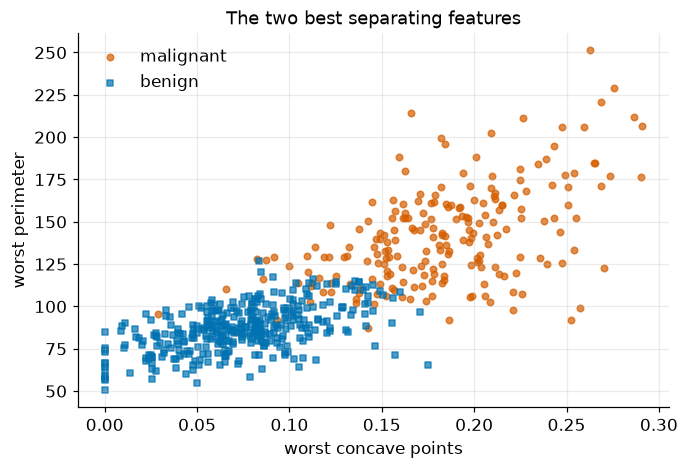


correlation of 'mean radius' and 'mean perimeter': 0.9979


In [11]:
def solution_2_8():
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_breast_cancer

    bc = load_breast_cancer(as_frame=True)
    df = bc.frame
    X, t = df.drop(columns="target"), df["target"]

    # (a) classes
    print("target names (index = code):", dict(enumerate(bc.target_names.tolist())))
    print("samples per class:", t.value_counts().sort_index().to_dict())

    # (b) standardized difference between the class means (pooled standard deviation)
    n0, n1 = (t == 0).sum(), (t == 1).sum()
    m0, m1 = X[t == 0].mean(), X[t == 1].mean()
    pooled = np.sqrt(((n0 - 1) * X[t == 0].var() + (n1 - 1) * X[t == 1].var()) / (n0 + n1 - 2))
    d = ((m0 - m1).abs() / pooled).sort_values(ascending=False)
    print("\nfive best separating features:")
    print(d.head(5).round(2).to_string())
    print("\nthree worst:")
    print(d.tail(3).round(2).to_string())

    # (c) scatter plot of the two best features
    f1, f2 = d.index[:2]
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    for code, color, marker in [(0, VERMILION, "o"), (1, BLUE, "s")]:
        sel = t == code
        ax.scatter(X.loc[sel, f1], X.loc[sel, f2], s=18, color=color, marker=marker, alpha=0.7, label=bc.target_names[code])
    ax.set(xlabel=f1, ylabel=f2, title="The two best separating features")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

    # (d) redundancy between two features
    print(f"\ncorrelation of 'mean radius' and 'mean perimeter': {df['mean radius'].corr(df['mean perimeter']):.4f}")

solution_2_8()

(a) The data set has 212 malignant tumors (code 0) and 357 benign ones (code 1). (b) The features describing the "worst" (largest) values of the concave points, the perimeter, and the radius, together with the mean concave points, separate the classes best: the class means differ by 2.5 to 2.7 pooled standard deviations, and the mean perimeter is fifth with 2.3. The worst features, the symmetry error, the texture error, and the mean fractal dimension, have a difference of at most 0.03 pooled standard deviations: the two classes look the same in these variables, taken one at a time. (c) In the scatter plot the two classes form two clouds with only a small overlap. (d) The correlation between `mean radius` and `mean perimeter` is 0.998: the perimeter of a nearly round tumor is just $2\pi$ times its radius, so the two columns carry the same information. A linear model with both features has almost linearly dependent columns (Exercise 1.10): the weights become unstable and hard to interpret, which is one of the reasons for the regularization of Chapter 6 and the feature selection of Chapter 10.

  n   uniform  exponential
  1    0.0577       0.1587
  2    0.0171       0.0956
  3    0.0106       0.0776
  5    0.0063       0.0611
 10    0.0033       0.0443

slope of log(KS) against log(n): uniform -1.21, exponential -0.54


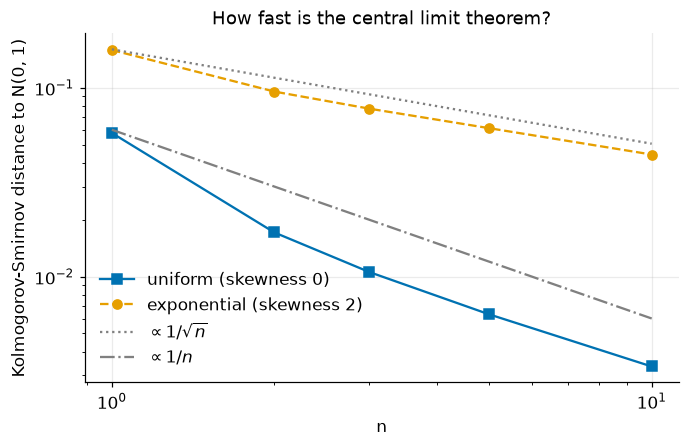

In [12]:
def solution_2_9():
    import matplotlib.pyplot as plt
    from scipy import stats

    rng = np.random.default_rng(SEED)
    reps, ns = 200_000, [1, 2, 3, 5, 10]
    uniform = rng.random((reps, max(ns)))                 # mean 1/2, standard deviation sqrt(1/12)
    exponential = rng.exponential(1.0, size=(reps, max(ns)))   # mean 1, standard deviation 1

    def ks_distance(samples, mu, sigma, n):
        z = (samples[:, :n].mean(axis=1) - mu) * np.sqrt(n) / sigma
        return stats.kstest(z, "norm").statistic

    ks_uniform = np.array([ks_distance(uniform, 0.5, np.sqrt(1 / 12), n) for n in ns])
    ks_expon = np.array([ks_distance(exponential, 1.0, 1.0, n) for n in ns])

    print(f"{'n':>3} {'uniform':>9} {'exponential':>12}")
    for n, a, b in zip(ns, ks_uniform, ks_expon):
        print(f"{n:>3} {a:>9.4f} {b:>12.4f}")
    slope_u = np.polyfit(np.log(ns), np.log(ks_uniform), 1)[0]
    slope_e = np.polyfit(np.log(ns), np.log(ks_expon), 1)[0]
    print(f"\nslope of log(KS) against log(n): uniform {slope_u:.2f}, exponential {slope_e:.2f}")

    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.loglog(ns, ks_uniform, "s-", color=BLUE, label="uniform (skewness 0)")
    ax.loglog(ns, ks_expon, "o--", color=ORANGE, label="exponential (skewness 2)")
    grid = np.array(ns, dtype=float)
    ax.loglog(grid, 0.16 / np.sqrt(grid), ":", color="gray", label=r"$\propto 1/\sqrt{n}$")
    ax.loglog(grid, 0.06 / grid, "-.", color="gray", label=r"$\propto 1/n$")
    ax.set(xlabel="n", ylabel="Kolmogorov-Smirnov distance to N(0, 1)", title="How fast is the central limit theorem?")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

solution_2_9()

The distance to the Gaussian shrinks for both distributions, but at different speeds: the slope on the log-log plot is about $-0.54$ for the exponential distribution (close to the $-1/2$ of an error proportional to $1/\sqrt{n}$) and about $-1.2$ for the uniform one, whose error shrinks like $1/n$ (the fitted slopes are estimates, and for the uniform at $n = 10$ the distance, about 0.003, is already close to the noise level of the experiment, of the order of $1/\sqrt{200{,}000}$). The explanation is the **skewness**. The leading error term in the central limit theorem is proportional to the skewness of the original distribution divided by $\sqrt{n}$. The exponential distribution is strongly skewed (skewness 2), so this term is present; the uniform distribution is symmetric (skewness 0), the term vanishes, and the next one, of order $1/n$, dominates. In practice: for symmetric, light-tailed data the Gaussian approximation of an average is excellent already with a handful of samples; for skewed or heavy-tailed data it needs many more.

In [13]:
def solution_2_10():
    from sklearn.datasets import load_wine
    from sklearn.feature_selection import SelectKBest, f_classif
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

    X, y = load_wine(return_X_y=True)
    seeds = range(30)

    # (a) scalers and k
    def mean_accuracy(make_model, k):
        scores = []
        for seed in seeds:
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
            scores.append(make_model(k).fit(X_tr, y_tr).score(X_te, y_te))
        return np.mean(scores)

    makers = {
        "no scaling":      lambda k: KNeighborsClassifier(n_neighbors=k),
        "standardization": lambda k: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
        "min-max":         lambda k: make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k)),
        "robust":          lambda k: make_pipeline(RobustScaler(), KNeighborsClassifier(n_neighbors=k)),
    }
    table = pd.DataFrame({name: {f"k = {k}": mean_accuracy(maker, k) for k in (1, 5, 15)} for name, maker in makers.items()})
    print("(a) mean test accuracy over 30 splits:")
    print(table.round(3).to_string())

    # (b) leakage through the scaler
    print("\n(b) scaling the whole data set before splitting (leak) against the pipeline:")
    X_scaled_all = StandardScaler().fit_transform(X)                  # the mistake: statistics of the test samples are used
    for k in (1, 5, 15):
        diffs, leak_scores, ok_scores = [], [], []
        for seed in seeds:
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
            Z_tr, Z_te, _, _ = train_test_split(X_scaled_all, y, test_size=0.3, stratify=y, random_state=seed)
            leak = KNeighborsClassifier(n_neighbors=k).fit(Z_tr, y_tr).score(Z_te, y_te)
            ok = makers["standardization"](k).fit(X_tr, y_tr).score(X_te, y_te)
            leak_scores.append(leak); ok_scores.append(ok); diffs.append(leak - ok)
        print(f"  k = {k:>2}: leak {np.mean(leak_scores):.4f} | pipeline {np.mean(ok_scores):.4f} | "
              f"difference {np.mean(diffs):+.4f} (std over splits {np.std(diffs):.4f})")

    # (c) leakage through label-based feature selection, on pure noise
    rng = np.random.default_rng(SEED)
    leak_scores, ok_scores = [], []
    for rep in range(30):
        X_noise = rng.normal(size=(60, 2000))
        y_noise = rng.integers(0, 2, size=60)                          # random labels: nothing can be learned
        X_sel = SelectKBest(f_classif, k=10).fit_transform(X_noise, y_noise)     # the mistake: selection sees all labels
        X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y_noise, test_size=0.3, random_state=rep)
        leak_scores.append(KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr).score(X_te, y_te))
        X_tr, X_te, y_tr, y_te = train_test_split(X_noise, y_noise, test_size=0.3, random_state=rep)
        pipe = make_pipeline(SelectKBest(f_classif, k=10), KNeighborsClassifier(n_neighbors=5))
        ok_scores.append(pipe.fit(X_tr, y_tr).score(X_te, y_te))
    print("\n(c) pure noise, selection of 10 features out of 2000, 5-NN, 30 repetitions:")
    print(f"  selection before the split (leak): accuracy {np.mean(leak_scores):.3f} +/- {np.std(leak_scores):.3f}")
    print(f"  selection inside the pipeline    : accuracy {np.mean(ok_scores):.3f} +/- {np.std(ok_scores):.3f}")

solution_2_10()

(a) mean test accuracy over 30 splits:
        no scaling  standardization  min-max  robust
k = 1        0.733            0.953    0.955   0.948
k = 5        0.699            0.960    0.960   0.947
k = 15       0.691            0.962    0.968   0.953

(b) scaling the whole data set before splitting (leak) against the pipeline:
  k =  1: leak 0.9531 | pipeline 0.9531 | difference +0.0000 (std over splits 0.0000)


  k =  5: leak 0.9593 | pipeline 0.9605 | difference -0.0012 (std over splits 0.0095)
  k = 15: leak 0.9605 | pipeline 0.9617 | difference -0.0012 (std over splits 0.0082)



(c) pure noise, selection of 10 features out of 2000, 5-NN, 30 repetitions:
  selection before the split (leak): accuracy 0.820 +/- 0.067
  selection inside the pipeline    : accuracy 0.520 +/- 0.093


(a) Without scaling the accuracy is about 0.70 to 0.73; with any of the three scalers it is about 0.95 to 0.97. Standardization and min-max scaling are practically equivalent on this data set (min-max is slightly better for $k = 15$), and the robust scaler is a bit behind. The best $k$ depends on the scaler, which is a first hint that $k$ must be tuned (Chapter 5).

(b) Scaling the whole data set before the split gives results that differ from the correct pipeline by about $0.001$ or less on average, with a standard deviation over the splits of about 0.01 (for $k = 1$ the accuracies are even identical on every split): the difference is not systematic, it is lost in the noise. The reason is that the mean and standard deviation of 178 samples hardly change when 30% of the samples are left out: a scaler learns very little from the data. This is why leakage through scalers often goes unnoticed. It would be a mistake to conclude that the rule is unimportant.

(c) On random labels no method can be better than chance, so the correct accuracy is 0.5, and the pipeline indeed gives about 0.52. The "leaky" procedure reaches about 0.82: among 2000 random features, some happen to correlate with the random labels *of the whole data set, test samples included*, and keeping the ten best of them builds the test labels into the features. The model seems to have found real structure and has found none. The more the preprocessing step *learns*, in particular when it uses the labels, the larger the leak: **every step that is fitted must be inside the pipeline.**

## C.3 Chapter 3

### Manual exercises

**Solution 3.1 — The Bayes classifier with unequal priors.**

(a) With $\pi_0 = 0.8$, $\pi_1 = 0.2$, the Bayes classifier predicts class 1 when $\pi_1 p_1(x) > \pi_0 p_0(x)$:
$$
0.2\,e^{-(x-2)^2/2} > 0.8\,e^{-x^2/2}
\iff -\tfrac{(x-2)^2}{2} + \tfrac{x^2}{2} > \ln 4
\iff 2x - 2 > \ln 4
\iff x > 1 + \tfrac{\ln 4}{2} \approx 1.693.
$$
The threshold is **not** the midpoint $x = 1$: the rarer class must be more convincing, so the boundary moves toward its mean by $\sigma^2\ln(\pi_0/\pi_1)/(\mu_1 - \mu_0) = 0.693$.

(b) With $t = 1 + \tfrac{\ln 4}{2}$, the two error probabilities are $\mathbb{P}(x > t \mid y = 0) = 1 - \Phi(t) = 0.0452$ and $\mathbb{P}(x \le t \mid y = 1) = \Phi(t - 2) = \Phi(-0.307) = 0.3795$, so
$$
R^\ast = 0.8 \cdot 0.0452 + 0.2 \cdot 0.3795 = 0.1121.
$$

(c) "Always predict 0" is wrong exactly on class 1: $R = 0.2$. The midpoint rule has $R = 0.8\,(1 - \Phi(1)) + 0.2\,\Phi(-1) = \Phi(-1) = 0.1587$ (the two error probabilities are equal, so the priors do not matter). The Bayes classifier, with $0.1121$, is better than both: ignoring the priors costs $0.1587 - 0.1121 = 0.0466$, and ignoring the input entirely costs $0.2 - 0.1121 = 0.0879$.

**Solution 3.2 — Which prediction does each loss prefer?**

(a) Add and subtract $\eta(\mathbf{x})$ inside the square:
$$
(y - f)^2 = (y - \eta)^2 + 2\,(y - \eta)(\eta - f) + (\eta - f)^2 .
$$
Condition on $\mathbf{x}$: $\eta(\mathbf{x})$ and $f(\mathbf{x})$ are constants, and $\mathbb{E}[y - \eta(\mathbf{x}) \mid \mathbf{x}] = 0$, so the expectation of the cross term is $\mathbb{E}\big[2\,(\eta - f)\,\mathbb{E}[y - \eta \mid \mathbf{x}]\big] = 0$. Taking the expectation of the other two terms gives the result. Its first term is $R^\ast$ and does not depend on $f$; the second is non-negative and zero only for $f = \eta$.

(b) For $y$ uniform on $\{0, 1, 10\}$ the mean is $11/3 = 3.667$ and the variance is $101/3 - (11/3)^2 = 20.22$. The squared loss $\mathbb{E}[(y - a)^2] = 20.22 + (a - 3.667)^2$ is minimized by the **mean** $a = 3.667$. The expected absolute loss is piecewise linear in $a$ with kinks at the data values; its slope is $\tfrac13(\#\{y_i < a\} - \#\{y_i > a\})$, negative for $a < 1$ and positive for $a > 1$, so the minimum is at the **median** $a = 1$.

| Constant | $\mathbb{E}[(y - a)^2]$ | $\mathbb{E}\lvert y - a\rvert$ |
|---|---|---|
| mean, $a = 3.667$ | **20.22** | 4.22 |
| median, $a = 1$ | 27.33 | **3.33** |

Each constant wins on its own loss. The outlier (the value 10) drags the mean away from the bulk of the data and contributes with its *square* to the squared loss; the median is not moved by how far the outlier is. This is the reason why the absolute loss is called *robust*, and why the choice of the loss is part of the specification of the problem.

**Solution 3.3 — Sizing a test set.** Here $\varepsilon = 0.03$ and $\delta = 0.05$.

(a) Hoeffding: $n \ge \ln(2/\delta)/(2\varepsilon^2) = \ln 40/0.0018 = 2049.4$, so **2050** examples.

(b) Chebyshev, with $\sigma^2 \le \tfrac14$: $n \ge \sigma^2/(\varepsilon^2\delta) = 0.25/(0.0009 \cdot 0.05) = 5555.6$, so **5556** examples: 2.7 times more than Hoeffding.

(c) With $p = 0.05$, $\sigma^2 = p(1 - p) = 0.0475$ and $n \ge 0.0475/(0.0009 \cdot 0.05) = 1055.6$, so **1056** examples, about half of the Hoeffding value. Hoeffding uses only the range $[0, 1]$ of the variable, and must hold for the *worst* variable of that range ($p = \tfrac12$, variance $\tfrac14$); Chebyshev uses the actual variance, which for a rare event is 5 times smaller. The ratio of the two sample sizes is $2\sigma^2/(\delta\ln(2/\delta))$, which is $0.51$ here. Chebyshev's dependence on $\delta$ is much worse ($1/\delta$ instead of $\ln(1/\delta)$), so for a smaller $\delta$ Hoeffding wins again: with $\delta = 10^{-4}$ it needs 5,502 examples against 527,778 for Chebyshev with the same variance $0.0475$. (Bernstein's inequality, not covered here, uses the variance *and* has the logarithmic dependence on $\delta$.)

(d) For $m = 1000$: $\sqrt{\ln(40)/2000} = 0.043$, that is $\pm 4.3$ percentage points.

**Solution 3.4 — The realizable case.**

(a) Call a function $f$ **bad** if $R(f) > \varepsilon$. A bad function is consistent with one random example with probability $1 - R(f) < 1 - \varepsilon$, and with all $n$ independent examples with probability at most $(1 - \varepsilon)^n \le e^{-\varepsilon n}$ (because $1 - u \le e^{-u}$). The ERM output has zero training error, so if $R(\hat f) > \varepsilon$ some bad function is consistent with the whole sample. By the union bound over at most $\lvert\mathcal{H}\rvert$ bad functions, $\mathbb{P}(R(\hat f) > \varepsilon) \le \lvert\mathcal{H}\rvert\,e^{-\varepsilon n}$.

(b) Setting $\lvert\mathcal{H}\rvert\,e^{-\varepsilon n} \le \delta$ gives $n \ge (\ln\lvert\mathcal{H}\rvert + \ln(1/\delta))/\varepsilon$. For the conjunctions, $\ln 3^{10} = 10.99$ and $\ln(1/0.01) = 4.61$, so $n \ge 15.59/0.05 = 311.8$: **312 examples**.

(c) In the agnostic case Corollary 3.2 gives an estimation error of at most $2\varepsilon'$ with $\varepsilon' = \sqrt{(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta))/(2n)}$; setting $2\varepsilon' = 0.05$ gives $n \ge 4\,(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta))/(2 \cdot 0.05^2) = 4 \cdot 16.28/0.005 =$ **13,028 examples**, about 42 times more. The difference is in the dependence on the accuracy: **$1/\varepsilon$** when the training error can be zero, **$1/\varepsilon^2$** in general. In the realizable case a function with true risk $\varepsilon$ is eliminated very quickly, because a mistake on it is *certain* to appear in the sample if it is made often enough; in the agnostic case the empirical risks of good and almost good functions differ by amounts of order $\varepsilon$ that fluctuate with standard deviation of order $1/\sqrt{n}$, and telling them apart takes $n \sim 1/\varepsilon^2$.

**Solution 3.5 — Why $\sqrt{\ln m}$?**

(a) For any $s > 0$, Jensen's inequality for the convex function $z \mapsto e^{sz}$ gives
$$
e^{s\,\mathbb{E}[\max_j Z_j]} \le \mathbb{E}\big[e^{s\max_j Z_j}\big] = \mathbb{E}\big[\max_j e^{sZ_j}\big] \le \sum_{j=1}^m \mathbb{E}\big[e^{sZ_j}\big] \le m\,e^{s^2\sigma^2/2}.
$$
(The maximum of non-negative numbers is at most their sum; this is the union bound in disguise, and requires no independence.) Taking logarithms and dividing by $s$,
$$
\mathbb{E}\big[\max_j Z_j\big] \le \frac{\ln m}{s} + \frac{s\sigma^2}{2}.
$$
The right-hand side is minimized at $s = \sqrt{2\ln m}/\sigma$, where it equals $\sigma\sqrt{2\ln m}$. (For $m = 1$ the bound is $0$, which also follows from $s \to 0$.)

(b) Let $Z_j = \mu - \hat{R}_j = \tfrac1n\sum_{i=1}^n(\mu - \ell_{ji})$ be an average of $n$ independent centered variables, where each term $(\mu - \ell_{ji})/n$ lies in an interval of length $1/n$. By Hoeffding's lemma each term has $\mathbb{E}[e^{s(\mu - \ell_{ji})/n}] \le e^{s^2/(8n^2)}$, and the product of the $n$ independent factors is $\mathbb{E}[e^{sZ_j}] \le e^{s^2/(8n)}$, which is the hypothesis of (a) with $\sigma^2 = 1/(4n)$. Hence
$$
\mathbb{E}\big[\mu - \min_j\hat{R}_j\big] = \mathbb{E}\big[\max_j Z_j\big] \le \sqrt{\tfrac{1}{4n}}\sqrt{2\ln m} = \sqrt{\frac{\ln m}{2n}},
$$
the thin curves of Figure 3.4. Observe that independence *across candidates* was never used: the bound holds even if the $m$ candidates are strongly correlated (in that case it is just less tight). Only the *number* of candidates enters, through a logarithm, which is why we can afford enormous finite classes: $10^6$ candidates cost only $\sqrt{13.8/(2n)}$.

### Python exercises

In [14]:
def solution_3_6():
    from scipy import stats

    Sigma = np.array([[1.0, 0.5], [0.5, 1.0]])
    mu0, mu1 = np.array([0.0, 0.0]), np.array([2.0, 1.0])

    # (a) direction and threshold of the Bayes classifier (equal priors, equal covariances)
    w = np.linalg.solve(Sigma, mu1 - mu0)
    threshold = w @ (mu0 + mu1) / 2
    print(f"(a) w = {w.round(4)}, threshold = {threshold:.4f}: predict class 1 when w'x > threshold")

    # (b) Bayes risk from the Mahalanobis distance
    delta = np.sqrt((mu1 - mu0) @ w)
    print(f"(b) Delta = {delta:.4f}, Bayes risk Phi(-Delta/2) = {stats.norm.cdf(-delta / 2):.4f}")

    # (c) Monte Carlo
    rng = np.random.default_rng(SEED)
    n = 1_000_000
    y = rng.integers(0, 2, size=n)
    X = rng.multivariate_normal([0, 0], Sigma, size=n) + np.where(y[:, None] == 1, mu1, mu0)
    err_bayes = np.mean((X @ w > threshold) != y)
    print(f"(c) Monte Carlo risk of the Bayes classifier, n = 10^6: {err_bayes:.4f}")

    # (d) classifiers that use a single feature (threshold at the midpoint of the two means of that feature)
    for j in range(2):
        pred = X[:, j] > (mu0[j] + mu1[j]) / 2
        theory = stats.norm.cdf(-abs(mu1[j] - mu0[j]) / (2 * np.sqrt(Sigma[j, j])))
        print(f"(d) feature x{j + 1} alone: Monte Carlo {np.mean(pred != y):.4f}, theory Phi(-|dmu|/(2 sigma)) = {theory:.4f}")

    # Why x2 adds nothing: E[x2 | x1] is the same line in both classes
    slope = Sigma[0, 1] / Sigma[0, 0]
    for k, mu in enumerate((mu0, mu1)):
        print(f"E[x2 | x1, class {k}] = {mu[1] - slope * mu[0]:.1f} + {slope:.1f} x1")


solution_3_6()

(a) w = [2. 0.], threshold = 2.0000: predict class 1 when w'x > threshold
(b) Delta = 2.0000, Bayes risk Phi(-Delta/2) = 0.1587
(c) Monte Carlo risk of the Bayes classifier, n = 10^6: 0.1590
(d) feature x1 alone: Monte Carlo 0.1590, theory Phi(-|dmu|/(2 sigma)) = 0.1587
(d) feature x2 alone: Monte Carlo 0.3085, theory Phi(-|dmu|/(2 sigma)) = 0.3085
E[x2 | x1, class 0] = 0.0 + 0.5 x1
E[x2 | x1, class 1] = 0.0 + 0.5 x1


(a) For equal covariances and equal priors the Bayes classifier is linear: $\mathbf{w} = \boldsymbol\Sigma^{-1}(\boldsymbol\mu_1 - \boldsymbol\mu_0) = (2, 0)^\top$ and the threshold is $\mathbf{w}^\top(\boldsymbol\mu_0 + \boldsymbol\mu_1)/2 = 2$: predict class 1 when $2x_1 > 2$, that is $x_1 > 1$. The classifier **does not use $x_2$ at all**. (b) $\Delta^2 = \mathbf{w}^\top(\boldsymbol\mu_1 - \boldsymbol\mu_0) = 4$, so $R^\ast = \Phi(-1) = 0.1587$, and (c) the Monte Carlo value $0.1590$ agrees within the sampling error (about $0.0004$ for $10^6$ points).

(d) The feature $x_1$ alone reaches the Bayes risk, $0.1587$; the feature $x_2$ alone gives $\Phi(-0.5) = 0.3085$, which is much better than chance. Both facts are consistent: $x_2$ *is* informative by itself, because it is correlated with $x_1$ and the class shifts both means, but **given $x_1$ it adds nothing**, since the conditional mean $\mathbb{E}[x_2 \mid x_1] = 0.5\,x_1$ is the same line in the two classes. This is the first example of a principle that will return in feature selection (Chapter 10): the usefulness of a feature depends on which other features are already available.

In [15]:
def solution_3_7():
    rng = np.random.default_rng(SEED)
    sigma = 0.3

    def draw(n):
        x = rng.uniform(0, 1, n)
        return x, np.sin(2 * np.pi * x) + rng.normal(0, sigma, n)

    x_big, y_big = draw(100_000)
    x_test, y_test = draw(100_000)
    rows = []
    for m in (1, 3, 6):
        f_H = np.polyfit(x_big, y_big, m)
        risk_H = np.mean((y_test - np.polyval(f_H, x_test)) ** 2)
        approx = risk_H - sigma ** 2
        for n in (30, 300):
            risks = []
            for _ in range(300):
                x, y = draw(n)
                coef = np.polyfit(x, y, m)
                risks.append(np.mean((y_test - np.polyval(coef, x_test)) ** 2))
            rows.append({"degree m": m, "n": n, "R(f_H)": risk_H, "approximation": approx,
                         "E[R(f_S)]": np.mean(risks), "estimation": np.mean(risks) - risk_H,
                         "median R(f_S)": np.median(risks)})
    table = pd.DataFrame(rows)
    print(f"Bayes risk R* = {sigma ** 2:.4f}")
    print(table.round(4).to_string(index=False))


solution_3_7()

Bayes risk R* = 0.0900
 degree m   n  R(f_H)  approximation  E[R(f_S)]  estimation  median R(f_S)
        1  30  0.2830         0.1930     0.3044      0.0214         0.2981
        1 300  0.2830         0.1930     0.2851      0.0021         0.2845
        3  30  0.0942         0.0042     0.1110      0.0168         0.1065
        3 300  0.0942         0.0042     0.0956      0.0014         0.0953
        6  30  0.0899        -0.0001     0.1911      0.1012         0.1180
        6 300  0.0899        -0.0001     0.0921      0.0022         0.0919


The approximation errors are $0.193$ for lines ($m = 1$, a sine period cannot be fitted by a line), $0.004$ for cubics and about zero for $m = 6$ (the value $-0.0001$ is a Monte Carlo error; the sine is almost exactly a degree-6 polynomial on $[0, 1]$). The estimation error is the opposite: it is largest for the richest class and shrinks with $n$.

At $n = 30$ the best degree is $m = 3$ (mean risk $0.111$ against $0.304$ for $m = 1$ and $0.191$ for $m = 6$), at $n = 300$ it is $m = 6$ ($0.0921$ against $0.0956$ for $m = 3$): **the best complexity grows with the sample size**, as in Figure 3.3. The mean risk of $m = 6$ at $n = 30$ is much larger than its median ($0.191$ against $0.118$): a few of the 300 samples produce a polynomial that oscillates wildly near the edges of $[0, 1]$ and has an enormous risk. This is *variance* in its purest form, a rich class reacting to the idiosyncrasies of one small sample; a degree-9 polynomial fitted to 20 points has such an extreme mean risk, dominated by a handful of samples, that the mean is meaningless. Chapter 4 formalizes it with the bias–variance decomposition.

In [16]:
def solution_3_8():
    from itertools import product

    def dichotomies(points, rule_family):
        return len({tuple(rule(x) for x in points) for rule in rule_family(points)})

    def half_lines(points):                       # I[x > t]: thresholds between consecutive points
        cuts = np.concatenate(([points[0] - 1], (points[:-1] + points[1:]) / 2, [points[-1] + 1]))
        return [lambda x, t=t: int(x > t) for t in cuts]

    def interval_complements(points):             # I[x < a or x > b]
        cuts = np.concatenate(([points[0] - 1], (points[:-1] + points[1:]) / 2, [points[-1] + 1]))
        return [lambda x, a=a, b=b: int(x < a or x > b) for a in cuts for b in cuts if a <= b]

    print(" n | half-lines | n+1 | complements of intervals | n(n+1)/2+1")
    for n in range(1, 9):
        pts = np.arange(n, dtype=float)
        print(f"{n:>2} | {dichotomies(pts, half_lines):>10} | {n + 1:>3} | {dichotomies(pts, interval_complements):>24} | {n * (n + 1) // 2 + 1:>10}")

    # (b) sign(sin(omega x)) shatters x_j = 10^-j
    m = 6
    x = 10.0 ** -np.arange(1, m + 1)
    ok = 0
    for labels in product([-1, 1], repeat=m):
        b = (1 - np.array(labels)) / 2
        omega = np.pi * (1 + np.sum(b * 10.0 ** np.arange(1, m + 1)))
        ok += np.all(np.sign(np.sin(omega * x)) == np.array(labels))
    print(f"\nsign(sin(omega x)) reproduces {ok} of {2 ** m} labelings of the {m} points x_j = 10^-j")


solution_3_8()

 n | half-lines | n+1 | complements of intervals | n(n+1)/2+1
 1 |          2 |   2 |                        2 |          2
 2 |          3 |   3 |                        4 |          4
 3 |          4 |   4 |                        7 |          7
 4 |          5 |   5 |                       11 |         11
 5 |          6 |   6 |                       16 |         16
 6 |          7 |   7 |                       22 |         22
 7 |          8 |   8 |                       29 |         29
 8 |          9 |   9 |                       37 |         37

sign(sin(omega x)) reproduces 64 of 64 labelings of the 6 points x_j = 10^-j


(a) For $n$ distinct points on a line the half-lines produce $n + 1$ dichotomies (the threshold falls in one of the $n + 1$ gaps), so $\Pi(n) = n + 1$; since $\Pi(2) = 3 < 2^2$, no pair of points is shattered and $d_{\mathrm{VC}} = 1$. The complements of intervals produce $n(n + 1)/2 + 1$ dichotomies, exactly as the intervals do: the points labeled 0 form a contiguous block, which is empty or one of the $n(n+1)/2$ possible blocks. For $n = 2$ all four labelings are possible, but for $n = 3$ the labeling $(0, 1, 0)$ is not (its zeros are not contiguous), so $\Pi(3) = 7 < 8$ and $d_{\mathrm{VC}} = 2$. Both counts agree with the output above.

(b) The table confirms that all $2^6 = 64$ labelings of $x_j = 10^{-j}$ are reproduced by $\mathrm{sign}(\sin(\omega x))$ with the prescribed $\omega$. The proof for general $m$ is the one outlined in the hint: for $i > j$ the term $\pi b_i 10^{i-j}$ is an even multiple of $\pi$ (it is $\pi$ times a multiple of 10) and does not change the sign of the sine; the term $i = j$ gives $\pi b_j$; the terms with $i < j$ add up to less than $\pi/5$ and the term $\pi 10^{-j}$ is smaller still. So the argument of the sine lies in $(\pi b_j, \pi b_j + \pi/2) \bmod 2\pi$, where the sign is $+$ for $b_j = 0$ and $-$ for $b_j = 1$. A class with a single parameter can therefore shatter arbitrarily large sets: the **number of parameters is not the capacity**.

In [17]:
def solution_3_9():
    from sklearn.datasets import load_breast_cancer
    from sklearn.preprocessing import StandardScaler

    rng = np.random.default_rng(SEED)
    X30 = StandardScaler().fit_transform(load_breast_cancer().data)[rng.choice(569, 100, replace=False)]
    n = 100
    sigmas = rng.choice([-1.0, 1.0], size=(2000, n))
    rows = []
    for d in (30, 100, 300, 1000, 3000):
        X = np.hstack([X30, rng.normal(size=(n, d - 30))])
        S = sigmas @ X                                                   # 2000 x d: the sums sum_i sigma_i x_ij
        r2 = np.mean(np.linalg.norm(S, axis=1)) / n
        r1 = np.mean(np.max(np.abs(S), axis=1)) / n
        b2 = np.sqrt(np.sum(X ** 2)) / n
        b1 = np.max(np.linalg.norm(X, axis=0)) * np.sqrt(2 * np.log(2 * d)) / n
        rows.append({"d": d, "l2 ball": r2, "bound l2": b2, "l1 ball": r1, "bound l1": b1})
    table = pd.DataFrame(rows)
    print(table.round(4).to_string(index=False))
    print(f"\nl2 complexity grows by a factor {table['l2 ball'].iloc[-1] / table['l2 ball'].iloc[0]:.2f} from d = 30 to d = 3000 "
          f"(sqrt(3000/30) = {np.sqrt(100):.0f});")
    print(f"l1 complexity grows by a factor {table['l1 ball'].iloc[-1] / table['l1 ball'].iloc[0]:.2f}")


solution_3_9()

   d  l2 ball  bound l2  l1 ball  bound l1
  30   0.5202    0.5487   0.1873    0.3655
 100   0.9961    1.0019   0.2685    0.4157
 300   1.7337    1.7370   0.3071    0.4568
1000   3.1594    3.1607   0.3432    0.4979
3000   5.4748    5.4762   0.3732    0.5327

l2 complexity grows by a factor 10.52 from d = 30 to d = 3000 (sqrt(3000/30) = 10);
l1 complexity grows by a factor 1.99


The $\ell_2$ complexity grows like $\sqrt{d}$ (a factor 10.5 from $d = 30$ to $d = 3000$, against $\sqrt{100} = 10$) and the bound $\sqrt{\sum_i\lVert\mathbf{x}_i\rVert^2}/n$ is nearly exact, because the squared norms of the rows are dominated by the $d - 30$ noise coordinates, whose squares add up to about $d$ per row. The point of Proposition 3.6 is that the bound depends on the *norm* of the data and not on the dimension: if the norm grows with $d$, as it does when we append noise columns, so does the bound, and **bounding $\lVert\mathbf{w}\rVert_2 \le 1$ does not protect against a large number of irrelevant features of order 1 each**. The $\ell_1$ complexity grows only by a factor of 2, as $\sqrt{\ln 2d}$ (the maximum over $2d$ signed columns, each of which behaves like a Gaussian with the same variance proxy) and the bound follows with a small slack (ratio between 1.4 and 2). This is the mathematical reason why $\ell_1$ regularization (Lasso, Chapter 10) works well when there are many irrelevant features, *provided that the true weight vector has a small $\ell_1$ norm*, that is, that it is sparse.

In [18]:
def solution_3_10():
    from scipy import stats

    rng = np.random.default_rng(SEED)
    z = stats.norm.ppf(0.975)
    reps = 20_000
    rows = []
    for p in (0.03, 0.2):
        for m in (20, 50, 200):
            K = rng.binomial(m, p, size=reps)
            ph = K / m
            hoeff = np.sqrt(np.log(2 / 0.05) / (2 * m)) * np.ones(reps)
            wald = z * np.sqrt(ph * (1 - ph) / m)
            centre = (ph + z ** 2 / (2 * m)) / (1 + z ** 2 / m)
            half_w = z * np.sqrt(ph * (1 - ph) / m + z ** 2 / (4 * m ** 2)) / (1 + z ** 2 / m)
            for name, lo, hi in [("Hoeffding", ph - hoeff, ph + hoeff), ("Wald", ph - wald, ph + wald),
                                 ("Wilson", centre - half_w, centre + half_w)]:
                rows.append({"p": p, "m": m, "interval": name, "coverage": np.mean((lo <= p) & (p <= hi)),
                             "mean width": np.mean(hi - lo)})
    table = pd.DataFrame(rows).pivot(index=["p", "m"], columns="interval", values=["coverage", "mean width"])
    print(table.round(3).to_string())


solution_3_10()

          coverage               mean width              
interval Hoeffding   Wald Wilson  Hoeffding   Wald Wilson
p    m                                                   
0.03 20      1.000  0.458  0.979      0.607  0.097  0.198
     50      1.000  0.784  0.937      0.384  0.081  0.109
     200     1.000  0.933  0.944      0.192  0.046  0.049
0.20 20      1.000  0.924  0.957      0.607  0.335  0.326
     50      0.999  0.935  0.950      0.384  0.218  0.215
     200     1.000  0.941  0.959      0.192  0.110  0.110


**Hoeffding's interval is valid but very conservative**: its coverage is 1.000 (or 0.999) in every row, much above the nominal 0.95, and it is two to five times wider than the others (a half-width of 0.30 for $m = 20$, which is useless for estimating an error rate of 0.03). **The Wald interval fails where it matters:** for a small error rate and a small test set its coverage is only 0.46 ($p = 0.03$, $m = 20$) and 0.78 ($m = 50$), because when $K = 0$ it collapses to a point and in general it relies on a normal approximation that is not accurate for $mp < 5$. For $p = 0.2$ and $m \ge 50$ it is fine. **The Wilson interval** has coverage close to 0.95 in all cases (0.937 to 0.979) and a width that is similar to the Wald interval where the latter works and larger where the Wald fails. It is the interval to report in practice; the Clopper–Pearson interval (`method="exact"`) is a conservative alternative that guarantees coverage at least 0.95 at the price of being slightly wider. Hoeffding's interval remains the right tool when a *guaranteed* statement without any approximation is needed, and as the formula to plan the size of a test set in advance.